## Project: Bank Marketing Subscription Prediction
## Business Problem: The business problem is to determine whether a customer will subscribe to the bank's term deposit

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
## import dataset
df = pd.read_csv("bank-full.csv", sep=";")
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


## Exploratory Data Analysis (EDA)

In [3]:
print(df.shape)
print(df.head())
print(df.tail())

(45211, 17)
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  
       age           job   marital  education default  balance housing loan  \
45206   51    techni

In [4]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [5]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [6]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
df.duplicated().sum()

np.int64(0)

## Data Preprocessing

In [9]:
# Seperate X and Y
x = df.drop(columns = ['duration', 'y'])
y = df[['y']]

print(x.shape)
print(y.shape)

(45211, 15)
(45211, 1)


In [10]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [11]:
## Spliting the dataset into train and test set
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(36168, 15)
(9043, 15)
(36168, 1)
(9043, 1)


In [12]:
# Identify num columns
num_cols  = x_train.select_dtypes(include='number').columns
print(num_cols)

Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='str')


In [13]:
# Identify cat columns
cat_cols = x_train.select_dtypes(include='str').columns
print(cat_cols)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='str')


In [14]:
# Encode categorical columns
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown = 'ignore')
encoder.fit(x_train[cat_cols])
x_train_encoded = encoder.transform(x_train[cat_cols])
x_test_encoded = encoder.transform(x_test[cat_cols])

In [15]:
print(x_train_encoded.shape)
print(x_test_encoded.shape)

(36168, 44)
(9043, 44)


In [16]:
# Scale numerical feature
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train[num_cols])
x_test_scaled = sc.transform(x_test[num_cols])

print(x_train_scaled.shape)
print(x_test_scaled.shape)

(36168, 6)
(9043, 6)


In [17]:
# Combine the training features
X_train_final = np.hstack((x_train_scaled, x_train_encoded.toarray()))

# Combine the testing features
X_test_final = np.hstack((x_test_scaled, x_test_encoded.toarray()))

print(X_train_final.shape)
print(X_test_final.shape)
print(y_train.shape)
print(y_test.shape)

(36168, 50)
(9043, 50)
(36168, 1)
(9043, 1)


## Model Building

In [18]:
from sklearn.linear_model import LogisticRegression
cls = LogisticRegression(random_state = 0)
cls.fit(X_train_final, y_train)

C:\Users\hp\desktop\sample_project_2\env\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",0
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multic

In [19]:
# Make predictions
y_pred = cls.predict(X_test_final)

# Display the first 10 predictions
print(y_pred[:10])

['no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no']


In [38]:
print("Actual values:")
print(y_test[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
         y
3610    no
11677   no
33018   no
44323  yes
8119    no
38958   no
18496   no
4249    no
2214    no
28848   no

Predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no']


## Model Evaluation

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(y_test, y_pred, pos_label='yes')

# Recall
recall = recall_score(y_test, y_pred, pos_label='yes')

# F1-score
f1 = f1_score(y_test, y_pred, pos_label='yes')

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.8932876257879022
Precision: 0.6411960132890365
Recall: 0.1838095238095238
F1-score: 0.2857142857142857


In [41]:
cm = confusion_matrix(y_test, y_pred)

print(cm)
print(classification_report(y_test, y_pred))

[[7885  108]
 [ 857  193]]
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7993
         yes       0.64      0.18      0.29      1050

    accuracy                           0.89      9043
   macro avg       0.77      0.59      0.61      9043
weighted avg       0.87      0.89      0.87      9043



In [42]:
print(cls.classes_)

print(cls.predict_proba(X_test_final[:5]))

['no' 'yes']
[[0.98192516 0.01807484]
 [0.92049795 0.07950205]
 [0.88141233 0.11858767]
 [0.53907913 0.46092087]
 [0.94650454 0.05349546]]


In [44]:
## 0.3 threshold
y_prob = cls.predict_proba(X_test_final)
print(cls.classes_)

yes_prob = y_prob[:, 1]

threshold = 0.3

y_pred_new = np.where(yes_prob >= threshold, 'yes', 'no')

['no' 'yes']


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_new))
print("Precision:", precision_score(y_test, y_pred_new, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred_new, pos_label='yes'))
print("F1 Score:", f1_score(y_test, y_pred_new, pos_label='yes'))

Accuracy: 0.8870949906004645
Precision: 0.5229793977812995
Recall: 0.3142857142857143
F1 Score: 0.39262343842950626


In [46]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_new))

[[7692  301]
 [ 720  330]]


In [50]:
threshold = 0.2

y_pred_new = np.where(yes_prob >= threshold, 'yes', 'no')

In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_new))
print("Precision:", precision_score(y_test, y_pred_new, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred_new, pos_label='yes'))
print("F1 Score:", f1_score(y_test, y_pred_new, pos_label='yes'))

Accuracy: 0.8731615614287294
Precision: 0.4519326065411298
Recall: 0.4342857142857143
F1 Score: 0.4429334628460418


In [52]:
print(confusion_matrix(y_test, y_pred_new))

[[7440  553]
 [ 594  456]]


In [61]:
y_prob = cls.predict_proba(X_test_final)
print(y_prob)

yes_prob = y_prob[:, 1]
print(yes_prob)

[[0.98192516 0.01807484]
 [0.92049795 0.07950205]
 [0.88141233 0.11858767]
 ...
 [0.92959026 0.07040974]
 [0.98492747 0.01507253]
 [0.77850262 0.22149738]]
[0.01807484 0.07950205 0.11858767 ... 0.07040974 0.01507253 0.22149738]


In [62]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, yes_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7749595181498097


[0.         0.         0.         0.00037533 0.00037533]
[0.         0.00095238 0.00857143 0.00857143 0.01238095]


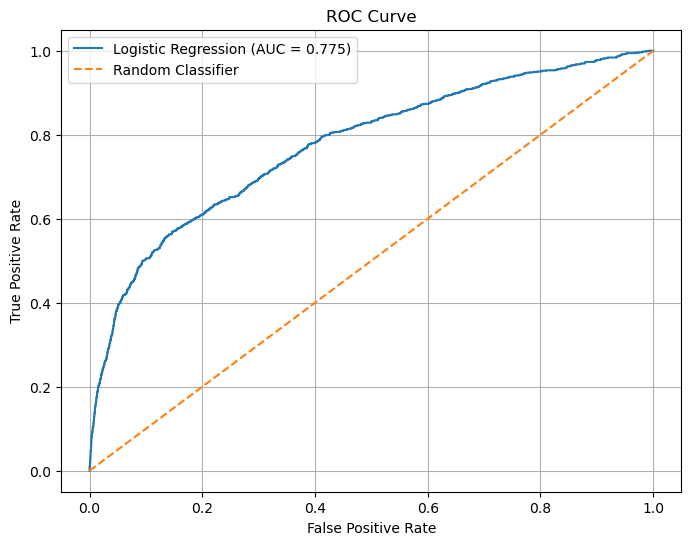

In [65]:
## Plotting ROC curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, yes_prob, pos_label='yes')

print(fpr[:5])
print(tpr[:5])

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend()
plt.grid(True)
plt.show()

## Hyperparameter using GridsearchCV

In [70]:
from sklearn.metrics import make_scorer, recall_score
recall_scorer = make_scorer(recall_score, pos_label='yes')

In [71]:
## import libraries
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

## Parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'class_weight': [None, 'balanced']
}

## Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Create GridSearchCV
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=5000, random_state=42),
    param_grid=param_grid,
   scoring=recall_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

## Fit GridSearchCV
grid_search.fit(X_train_final, y_train)

## Examine best result
print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation Recall:", grid_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


C:\Users\hp\desktop\sample_project_2\env\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Best Parameters: {'C': 0.01, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best Cross-Validation Recall: 0.6506192778062418


In [73]:
## Best model
best_model = grid_search.best_estimator_

In [74]:
y_pred_tuned = best_model.predict(X_test_final)

In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("Precision:", precision_score(y_test, y_pred_tuned, pos_label='yes'))

print("Recall:", recall_score(y_test, y_pred_tuned, pos_label='yes'))

print("F1 Score:", f1_score(y_test, y_pred_tuned, pos_label='yes'))

Accuracy: 0.7413468981532677
Precision: 0.26049795615013005
Recall: 0.6676190476190477
F1 Score: 0.37476610531943333


In [76]:
print(confusion_matrix(y_test, y_pred_tuned))

[[6003 1990]
 [ 349  701]]


In [77]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

          no       0.95      0.75      0.84      7993
         yes       0.26      0.67      0.37      1050

    accuracy                           0.74      9043
   macro avg       0.60      0.71      0.61      9043
weighted avg       0.87      0.74      0.78      9043



In [78]:
## Baseline model vs Tuned model
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Baseline model evaluation
baseline_results = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, pos_label='yes'),
    'Recall': recall_score(y_test, y_pred, pos_label='yes'),
    'F1 Score': f1_score(y_test, y_pred, pos_label='yes')
}

# Tuned model evaluation
tuned_results = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned, pos_label='yes'),
    'Recall': recall_score(y_test, y_pred_tuned, pos_label='yes'),
    'F1 Score': f1_score(y_test, y_pred_tuned, pos_label='yes')
}

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Baseline Model': baseline_results,
    'Tuned Model': tuned_results
})

# Convert values to percentages
comparison_df = comparison_df * 100

# Display results
print(comparison_df.round(2))

           Baseline Model  Tuned Model
Accuracy            89.33        74.13
Precision           64.12        26.05
Recall              18.38        66.76
F1 Score            28.57        37.48


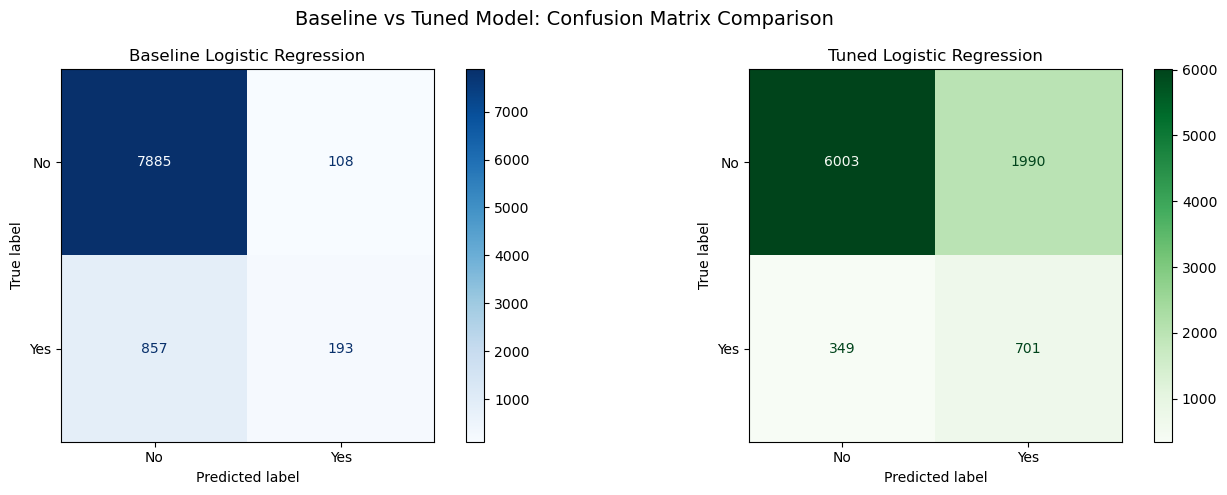

In [79]:
## Visiual confusion metric
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create confusion matrices
cm_baseline = confusion_matrix(y_test, y_pred, labels=['no', 'yes'])
cm_tuned = confusion_matrix(y_test, y_pred_tuned, labels=['no', 'yes'])

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline model
disp_baseline = ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=['No', 'Yes']
)

disp_baseline.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Baseline Logistic Regression')

# Tuned model
disp_tuned = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=['No', 'Yes']
)

disp_tuned.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('Tuned Logistic Regression')

# Overall title
plt.suptitle('Baseline vs Tuned Model: Confusion Matrix Comparison', fontsize=14)

plt.tight_layout()
plt.show()

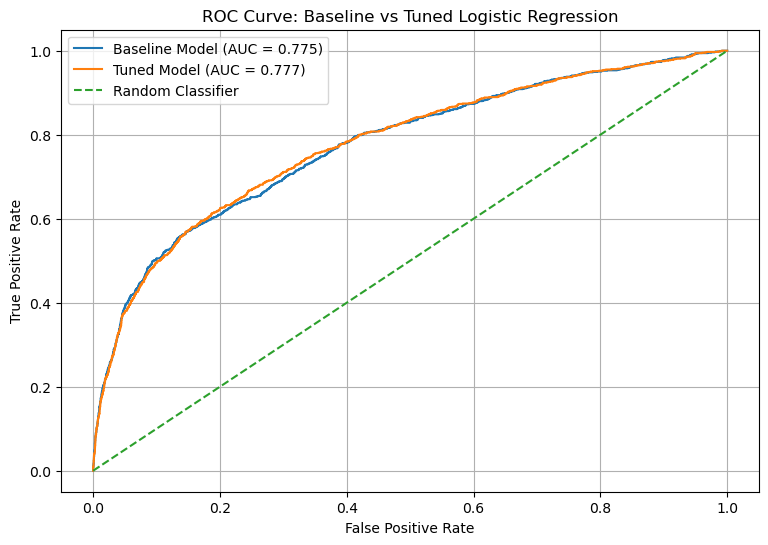

Baseline ROC-AUC: 0.775
Tuned ROC-AUC: 0.7772


In [80]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities
baseline_prob = cls.predict_proba(X_test_final)[:, 1]
tuned_prob = best_model.predict_proba(X_test_final)[:, 1]

# Calculate ROC curve for baseline model
fpr_baseline, tpr_baseline, _ = roc_curve(
    y_test, baseline_prob, pos_label='yes'
)

# Calculate ROC curve for tuned model
fpr_tuned, tpr_tuned, _ = roc_curve(
    y_test, tuned_prob, pos_label='yes'
)

# Calculate ROC-AUC scores
auc_baseline = roc_auc_score(y_test, baseline_prob)
auc_tuned = roc_auc_score(y_test, tuned_prob)

# Plot both ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_baseline,
    tpr_baseline,
    label=f'Baseline Model (AUC = {auc_baseline:.3f})'
)

plt.plot(
    fpr_tuned,
    tpr_tuned,
    label=f'Tuned Model (AUC = {auc_tuned:.3f})'
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Baseline vs Tuned Logistic Regression')

plt.legend()
plt.grid(True)
plt.show()

print("Baseline ROC-AUC:", round(auc_baseline, 4))
print("Tuned ROC-AUC:", round(auc_tuned, 4))

In [84]:
categorical_features = encoder.get_feature_names_out(cat_cols)

print(categorical_features)

['job_admin.' 'job_blue-collar' 'job_entrepreneur' 'job_housemaid'
 'job_management' 'job_retired' 'job_self-employed' 'job_services'
 'job_student' 'job_technician' 'job_unemployed' 'job_unknown'
 'marital_divorced' 'marital_married' 'marital_single' 'education_primary'
 'education_secondary' 'education_tertiary' 'education_unknown'
 'default_no' 'default_yes' 'housing_no' 'housing_yes' 'loan_no'
 'loan_yes' 'contact_cellular' 'contact_telephone' 'contact_unknown'
 'month_apr' 'month_aug' 'month_dec' 'month_feb' 'month_jan' 'month_jul'
 'month_jun' 'month_mar' 'month_may' 'month_nov' 'month_oct' 'month_sep'
 'poutcome_failure' 'poutcome_other' 'poutcome_success' 'poutcome_unknown']


In [85]:
feature_names = list(num_cols) + list(categorical_features)

print("Number of feature names:", len(feature_names))

Number of feature names: 50


In [86]:
coefficients = best_model.coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

print(coef_df.to_string(index=False))

            Feature  Coefficient
   poutcome_success     1.265281
          month_mar     0.753515
          month_oct     0.734380
          month_sep     0.549106
   contact_cellular     0.443802
        job_retired     0.432239
          month_dec     0.315726
        job_student     0.283308
         housing_no     0.259881
  contact_telephone     0.209977
            loan_no     0.206088
          month_jun     0.163891
     marital_single     0.156965
          month_apr     0.141788
 education_tertiary     0.135453
         default_no     0.117453
            balance     0.090126
  education_unknown     0.063454
           previous     0.051842
     job_unemployed     0.042613
   marital_divorced     0.041147
         job_admin.     0.040348
              pdays    -0.003873
                age    -0.009517
education_secondary    -0.022524
                day    -0.028140
     job_management    -0.046579
       job_services    -0.070997
     job_technician    -0.081615
        de

In [87]:
print("Feature names:", len(feature_names))
print("Model coefficients:", len(coefficients))

Feature names: 50
Model coefficients: 50


In [88]:
# Get the 10 strongest positive coefficients
top_positive = coef_df.nlargest(10, 'Coefficient')

# Get the 10 strongest negative coefficients
top_negative = coef_df.nsmallest(10, 'Coefficient')

In [89]:
top_features = pd.concat([top_positive, top_negative])

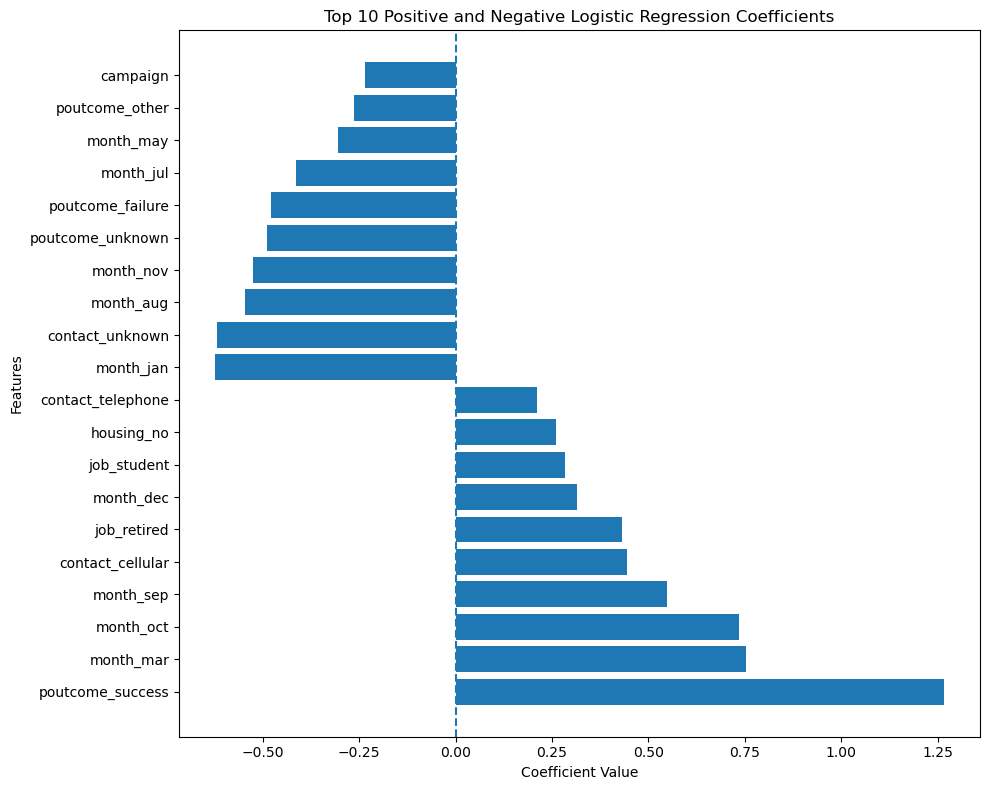

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.axvline(x=0, linestyle='--')

plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.title('Top 10 Positive and Negative Logistic Regression Coefficients')

plt.tight_layout()
plt.show()

## Save The Trained Model and Preprocessing Pipeline

In [93]:
import joblib

joblib.dump(best_model, 'bank_marketing_model.pkl')

joblib.dump(encoder, 'bank_marketing_encoder.pkl')

joblib.dump(num_cols, 'numerical_columns.pkl')

joblib.dump(cat_cols, 'categorical_columns.pkl')

['categorical_columns.pkl']